# เก็บและวิเคราะห์ข้อมูลหุ้นไทยจากเว็บ: กรณีศึกษา SET100

**Web data collection for finance research**

**วัตถุประสงค์การเรียนรู้** เมื่อจบบทนี้ ผู้เรียนจะสามารถ
1. อธิบายว่าหน้าเว็บส่งข้อมูลมาให้เบราว์เซอร์อย่างไร (HTML table, form, JSON endpoint) และใช้ `recon.py` สำรวจได้
2. ตรวจคุณภาพข้อมูลราคา เช่น split glitch และ Adj Close ที่ผิด และอธิบายผลต่อการวิเคราะห์
3. คำนวณผลตอบแทน ความผันผวน Sharpe ratio และ max drawdown
4. สร้าง screener หลายปัจจัย และ backtest กลยุทธ์ momentum พร้อมอธิบายข้อจำกัด เช่น survivorship bias และ look-ahead bias

> ให้รัน notebook จากโฟลเดอร์ `notebooks/` ของ repo

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analytics as a
pd.set_option('display.float_format', '{:.3f}'.format)

## 1. สำรวจหน้าเว็บก่อนเขียน scraper

หลักคือ หาแหล่งข้อมูลที่สะอาดที่สุดก่อน เช่น JSON endpoint ที่อยู่เบื้องหลังหน้าเว็บ แล้วค่อย parse HTML เป็นทางเลือกสุดท้าย ตัวอย่างนี้ใช้ HTML ปลอมที่สร้างขึ้นเอง เพื่อให้รันได้โดยไม่ต้องต่ออินเทอร์เน็ต

ขั้นตอนเต็มและเครื่องมือที่ใช้ดูได้ใน `docs/reverse-engineering-data-sources.md`

In [2]:
from recon import report_html
demo = '''<html><head><title>demo</title><script>fetch("/api/consensus.php?sector=BANK")</script></head>
<body><form action="view.php"><select name="sector"><option>BANK</option><option>ENERG</option></select></form>
<table><tr><th>Symbol</th><th>Target</th><th>Upside %</th></tr><tr><td>PTT</td><td>40</td><td>12%</td></tr></table></body></html>'''
report_html(demo)


title: demo

== tables: 1
[0] id=None class=None rows=2
    header: ['Symbol', 'Target', 'Upside %']
    row 1:  ['PTT', '40', '12%']

== forms: 1
  GET view.php
    select name=sector type=None value=None options=['BANK', 'ENERG']

== scripts
  inline scripts: 1

== candidate data endpoints / parameterised links: 2
   /api/consensus.php?sector=BANK
   view.php


**คำถามชวนคิด:** ถ้า `recon.py` ไม่เจอตารางใน HTML แต่เจอลิงก์ `/api/consensus.php` แปลว่าอะไร และขั้นต่อไปควรใช้เครื่องมือใด

**ข้อพิจารณาด้านจริยธรรมและกฎหมาย:** ตรวจ `robots.txt` และข้อกำหนดการใช้งานของเว็บก่อน ดึงข้อมูลช้าๆ อย่าหลบระบบล็อกอิน และระบุแหล่งข้อมูลต้นทาง (SET, IAA) ในงานวิจัยเสมอ

## 2. ตรวจคุณภาพข้อมูล

ข้อมูลราคาหุ้นไทยจาก Yahoo มีจุดผิดที่พบบ่อย 2 แบบ
- **Split glitch:** ราคากระโดดขึ้นหรือลงประมาณ 10 เท่าเป็นเวลาหนึ่งสัปดาห์ แล้วกลับมาที่เดิม
- **Adj Close ผิด:** ราคาปรับ (Adj Close) เปลี่ยนแบบขั้นบันได ทั้งที่ราคาปิด (Close) แทบไม่ขยับ

มาดูผลต่อผลตอบแทนรายสัปดาห์ เมื่อใช้ข้อมูลดิบเทียบกับข้อมูลที่ทำความสะอาดแล้ว

In [3]:
raw = {}
for t in ['PTT', 'KTC']:
    df = pd.read_csv(f'data/{t}.csv', parse_dates=['Date']).set_index('Date')
    raw[t] = df['Adj Close']
raw = pd.DataFrame(raw)
clean = a.load_prices()[['PTT', 'KTC']]
compare = pd.DataFrame({
    'raw max weekly return': raw.pct_change(fill_method=None).max(),
    'raw min weekly return': raw.pct_change(fill_method=None).min(),
    'clean max weekly return': clean.pct_change(fill_method=None).max(),
    'clean min weekly return': clean.pct_change(fill_method=None).min(),
})
compare

,raw max weekly return,raw min weekly return,clean max weekly return,clean min weekly return
PTT,9.093,-0.901,0.183,-0.233
KTC,8.921,-0.902,0.290,-0.298


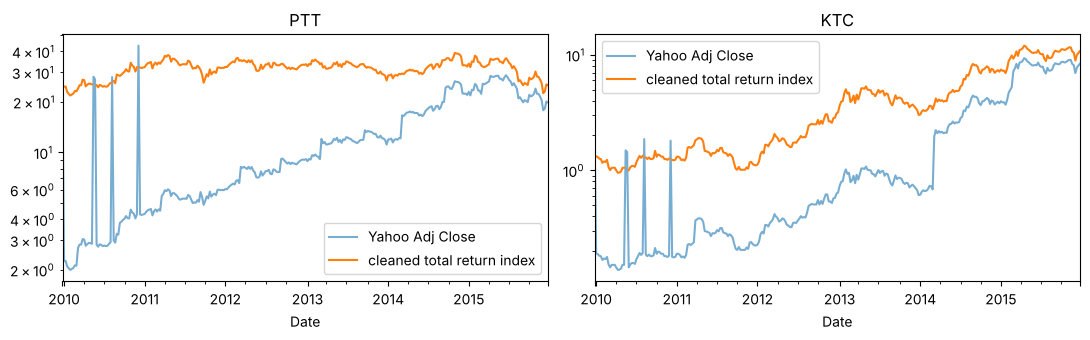

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i, t in enumerate(['PTT', 'KTC']):
    raw[t].loc[:'2015'].plot(ax=ax[i], label='Yahoo Adj Close', alpha=.6)
    clean[t].loc[:'2015'].plot(ax=ax[i], label='cleaned total return index')
    ax[i].set_title(t); ax[i].set_yscale('log'); ax[i].legend()
plt.tight_layout()

**แบบฝึกหัด 1:** เปิด `analytics.py` แล้วอ่านฟังก์ชัน `clean_prices` และ `total_return_index` จากนั้นลองเปลี่ยน `max_ratio` เป็น 3.0 แล้วดูว่าผลตอบแทนสูงสุดและต่ำสุดเปลี่ยนไปอย่างไร

## 3. ผลตอบแทนและความเสี่ยง

| ตัวชี้วัด | สูตร (ข้อมูลรายสัปดาห์) |
| --- | --- |
| CAGR | $(P_T/P_0)^{1/\text{years}} - 1$ |
| Volatility | $\sigma_{weekly}\sqrt{52}$ |
| Sharpe | $(\text{CAGR} - r_f)/\text{Volatility}$ |
| Max drawdown | $\min_t (P_t / \max_{s\le t} P_s - 1)$ |
| Dividend yield (ประมาณ) | ผลตอบแทนรวม 1 ปี − ผลตอบแทนจากราคา 1 ปี |

In [5]:
adj = a.load_prices()
close = a.load_prices(column='Close')
m = a.metrics(adj, close, rf=0.02)
print('ข้อมูลถึง', adj.index[-1].date(), '| จำนวนหุ้น', len(m))
m.sort_values('Sharpe', ascending=False).head(10)

ข้อมูลถึง 2026-10-19 | จำนวนหุ้น 99


,Start,End,CAGR,Volatility,Sharpe,MaxDrawdown,Return1Y,Momentum12_1,DividendYield1Y
Symbol,,,,,,,,,
TTB,2021-05-17,2026-10-19,0.244,0.208,1.079,-0.216,0.534,0.726,0.060
TISCO,2009-12-28,2026-10-19,0.182,0.226,0.716,-0.349,0.243,0.258,0.069
GULF,2017-12-04,2026-10-19,0.222,0.325,0.621,-0.312,0.424,0.401,0.055
AOT,2009-12-28,2026-10-19,0.189,0.274,0.617,-0.646,0.526,0.590,0.015
COM7,2015-08-10,2026-10-19,0.254,0.391,0.599,-0.750,0.355,0.243,0.051
KKP,2009-12-28,2026-10-19,0.175,0.268,0.577,-0.504,0.950,0.917,0.084
BDMS,2009-12-28,2026-10-19,0.154,0.240,0.559,-0.378,0.037,0.080,0.053
KTC,2010-01-04,2026-10-19,0.233,0.385,0.555,-0.709,0.241,0.312,0.062
ADVANC,2009-12-28,2026-10-19,0.147,0.230,0.552,-0.452,0.198,0.230,0.098


Text(0.5, 1.0, 'Risk vs return, SET100 (current members)')

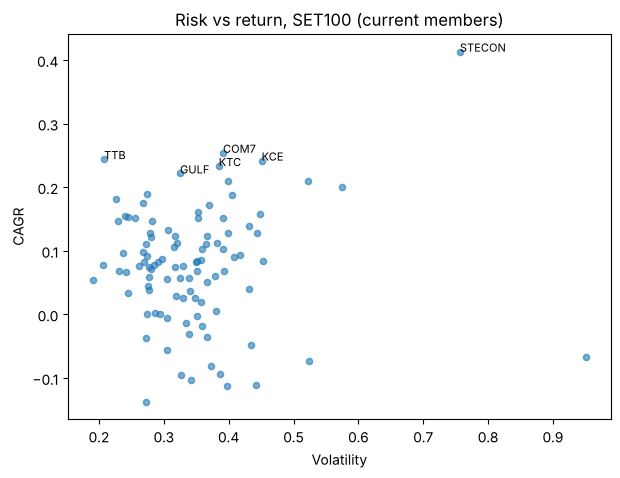

In [6]:
ax = m.plot.scatter(x='Volatility', y='CAGR', figsize=(7, 5), alpha=.6)
for t, r in m.nlargest(6, 'CAGR').iterrows():
    ax.annotate(t, (r.Volatility, r.CAGR), fontsize=8)
ax.set_title('Risk vs return, SET100 (current members)')

**คำถามชวนคิด:** ค่า CAGR มัธยฐานของหุ้นกลุ่มนี้สูงกว่าผลตอบแทนของดัชนี SET ในช่วงเดียวกันมาก เป็นเพราะอะไร (คำใบ้: หุ้นในรายชื่อคือหุ้นที่อยู่ใน SET100 *วันนี้*)

## 4. Screener หลายปัจจัย

คะแนนรวมคำนวณจาก z-score ของแต่ละปัจจัยคูณน้ำหนัก
- Momentum 12-1 (+0.35)
- Volatility (−0.25 ความผันผวนต่ำได้คะแนนดี)
- Dividend yield (+0.20)
- Consensus upside (+0.20 ใช้เฉพาะเมื่อมีข้อมูล `data/consensus/`)

ปัจจัยที่ไม่มีข้อมูลจะถูกตัดออกจากการคำนวณ ไม่ได้นับเป็นศูนย์

In [7]:
a.screen(m, a.load_latest_consensus()).head(15)[['Momentum12_1', 'Volatility', 'DividendYield1Y', 'Score']]

,Momentum12_1,Volatility,DividendYield1Y,Score
Symbol,,,,
TFG,1.332,0.400,0.105,1.172
SPRC,2.227,0.383,0.086,1.057
WHAUP,0.853,0.262,0.058,0.937
GUNKUL,1.627,0.404,0.051,0.916
AMATA,1.349,0.366,0.059,0.823
KTB,0.780,0.256,0.096,0.802
KKP,0.917,0.268,0.084,0.771
BCP,0.967,0.306,0.082,0.673
ADVANC,0.230,0.230,0.098,0.637


**แบบฝึกหัด 2:** ลองเปลี่ยนน้ำหนักเป็นแบบ value/defensive เช่น ให้ `DividendYield1Y` 0.5 และ `Volatility` −0.5 โดยส่งผ่านพารามิเตอร์ `weights=` แล้วเปรียบเทียบว่ารายชื่อหุ้น 10 อันดับแรกเปลี่ยนไปอย่างไร

In [8]:
a.screen(m, weights={'DividendYield1Y': 0.5, 'Volatility': -0.5}).head(10)[['DividendYield1Y', 'Volatility', 'Score']]

,DividendYield1Y,Volatility,Score
Symbol,,,
ADVANC,0.098,0.230,1.542
KTB,0.096,0.256,1.374
PTT,0.078,0.241,1.063
KKP,0.084,0.268,1.054
SCB,0.083,0.269,1.031
SIRI,0.092,0.320,0.974
TISCO,0.069,0.226,0.969
SPALI,0.080,0.281,0.924
KBANK,0.077,0.268,0.919


## 5. Backtest: momentum 12-1

- ทุก 4 สัปดาห์ เลือก 20 หุ้นที่ momentum สูงสุด ถือน้ำหนักเท่ากัน
- หักค่าธรรมเนียมซื้อขาย 20 bps ต่อ turnover
- เทียบกับพอร์ต equal-weight ที่ถือทุกตัว และกับดัชนี SET (ถ้ามีไฟล์ `data/index/SET.csv`)

,CAGR,Volatility,Sharpe,MaxDrawdown,Weeks
Momentum,0.182,0.186,0.868,-0.344,825.000
EqualWeight,0.127,0.172,0.624,-0.391,825.000


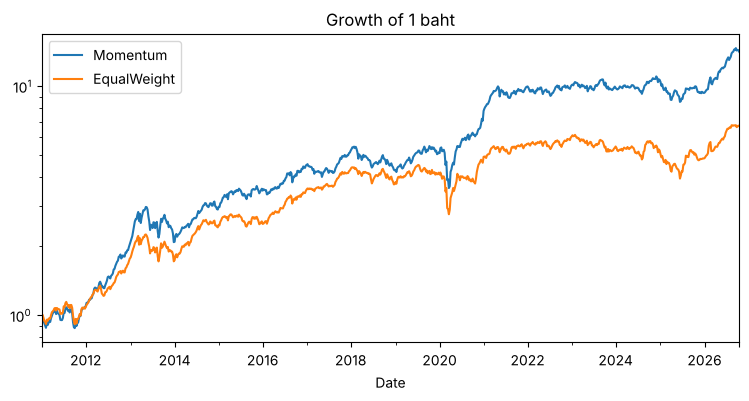

In [9]:
bt = a.backtest(adj, top=20, cost_bps=20)
idx = a.load_index()
if idx is not None:
    bt = bt.join(idx.pct_change(fill_method=None).rename('SET'), how='left')
(1 + bt.fillna(0)).cumprod().plot(logy=True, figsize=(9, 4), title='Growth of 1 baht')
a.summarize(bt)

**ข้อควรระวังในการตีความ backtest**
1. **Survivorship bias:** ใช้รายชื่อ SET100 ปัจจุบันย้อนหลัง จึงตัดหุ้นที่ถูกถอดหรือเพิกถอนออกไป ผลลัพธ์จึงดูดีเกินจริง
2. **Look-ahead bias:** สัญญาณคำนวณจากราคาถึงสัปดาห์ t และเริ่มถือหุ้นในสัปดาห์ t+1 (ดูใน `backtest()` ว่าใช้ `shift(1)` อย่างไร)
3. **Data-snooping:** ถ้าลองหลายพารามิเตอร์แล้วเลือกตัวที่ดีที่สุด ผลจะไม่สะท้อนอนาคต
4. **ต้นทุนจริง:** ยังไม่รวม spread, สภาพคล่อง และภาษีเงินปันผล

**แบบฝึกหัด 3:** รัน backtest ด้วย `top` = 10, 20, 30 และ `cost_bps` = 0, 20, 50 แล้วสร้างตาราง Sharpe ratio ผลที่ได้สอดคล้องกับงานวิจัยเรื่อง momentum ในตลาดเกิดใหม่หรือไม่ อ่านประกอบใน `docs/literature-review-analyst-forecasts.md`

In [10]:
grid = {}
for top in (10, 20, 30):
    for cost in (0, 20, 50):
        s = a.summarize(a.backtest(adj, top=top, cost_bps=cost))
        grid[(top, cost)] = s.loc['Momentum', 'Sharpe']
pd.Series(grid).unstack().rename_axis(index='top N', columns='cost bps')

cost bps,0,20,50
top N,,,
10,0.838,0.771,0.672
20,0.931,0.868,0.774
30,0.901,0.847,0.766


## 6. ต่อยอด

- ดึงข้อมูล analyst consensus ด้วย `consensus.py` ทุกวัน แล้วศึกษาว่าการปรับราคาเป้าหมายเกิดก่อนหรือหลังการเปลี่ยนแปลงของราคาหุ้น
- แก้ survivorship bias โดยใช้รายชื่อ SET100 ย้อนหลังของแต่ละรอบ ซึ่งดูได้จากประกาศของ SET ทุกครึ่งปี
- เปรียบเทียบผลกับดัชนีผลตอบแทนรวม (SET TRI)